# Investigation: damping of the LI-7500 fluxes in 2004-2007 (2004-2017)

**notebook version**: `1` (30 Oct 2026)

## ℹ️ About this notebook

The open-path LI-7500 (`IRGA75`) shows less summer daytime CO2 uptake in 2004-2007 than in the
later years, and the difference is already present in the uncorrected flux. In June-August at
midday (`SW_IN_POT` above 300 W m-2), the median raw covariance flux `FC_UNCORR` is -15.3 to
-17.1 µmol m-2 s-1 in 2004-2007 against -18.6 to -20.8 in 2008-2017. The H2O flux `FH2O` is 3.4 to 3.9 mmol m-2 s-1 in 2004-2007 and
3.7 to 5.5 in 2008-2017, highest in 2008-2010 (see the table in the load section). The analyser read CO2 about 2 % low in 2004-2005 and
about 6 % low in 2006-2007, until its recalibration in December 2007. A gain error of this size
accounts for about 0.5 µmol m-2 s-1 of the daytime flux. The investigation
[`OPCO_TRANSFER_CHECK_2004-2017`](OPCO_TRANSFER_CHECK_2004-2017.ipynb) found that the opco
correction is not larger in the early years and that the gap to the LI-7200 years lies in the
uncorrected flux.

**Question.** Did the LI-7500 measurement (time lag, signal, spectral response) damp the CO2 and
H2O fluxes in 2004-2007, and by how much?

A loss of covariance in the analyser or in the lag detection acts on both gases and leaves the
sensible heat flux `H`, which comes from the sonic anemometer alone, unchanged. The notebook checks:

1. **Processing settings.** Whether the EddyPro runs of 2004-2007 differ from the later runs.
2. **Time lags.** The detected lags of CO2 and H2O per year, the share that lies at the limits of
   the lag window, and the dependence of the lag on wind direction, which reflects the position of
   the analyser relative to the sonic.
3. **Analyser diagnostics.** The automatic gain control (AGC) of the LI-7500 per month and its
   relation to the flux.
4. **Concentration readings.** The CO2 mixing ratio against the background increase, and the H2O
   density against the humidity probe, as estimates of the gain of the analyser.
5. **Correlation coefficients at matched stability.** The correlation of the vertical wind with
   sonic temperature, CO2 and H2O, per year, for both analysers.
6. **Energy balance.** `LE` relative to the available energy, per year.
7. **Spectral correction and random uncertainty** per year.
8. **Implied adjustment.** The change of the 2005-2007 summer `NEE` if the reductions found in
   sections 4 and 5 are attributed to the analyser, and how much of the gap to the LI-7200 years
   it closes.

The notebook writes no file. It reads the outputs of the chain and the EddyPro settings files; no
input is changed.

### What is evidence and what is assumption

- **The correlation test (section 5) rests on flux-variance similarity.** In the surface layer the
  correlation coefficient of the vertical wind with a scalar depends on stability, not on the size
  of the flux. A smaller ecosystem flux therefore leaves it unchanged, while a covariance loss in
  the analyser or the lag detection lowers it. Two other effects also lower it: noise in the
  scalar signal, which does not bias the flux, and a change of the scalar sources, for example in a
  dry summer. The test therefore gives an upper bound for the damping, not an estimate.
- **The CO2 channel carries the self-heating of the LI-7500**, which adds an apparent uptake to the
  covariance. The H2O channel is affected by it only by about 1 %. The H2O correlation is therefore
  the cleaner measure of a damping by the analyser.
- **The concentration checks (section 4) give the gain only approximately.** A calibration error
  can be an error of the zero or of the span; only the span changes the flux in proportion.

### Known limitations

- **No measured radiation before September 2005.** The energy balance (section 6) starts in 2006.
- **The humidity probe changed in 2016** (Rotronic MP101A to Campbell CS215), so the H2O check of
  section 4 uses 2005-2015.
- **No raw data are used.** The tests use the half-hourly statistics of EddyPro. The covariance as
  a function of lag, the cospectra and the instrument noise are not available at this level.
- **The reference years have their own weather.** The early summers of 2004-2006 had drier soils
  than most later summers.

***

## 📇 Data sources

All files are read from the external data folder, by absolute path, and indexed on
`TIMESTAMP_MIDDLE`.

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet`: the
  EddyPro *FLUXNET* output of the LI-7500 runs with the opco correction (`FC_L1.1_OPCO`). The
  half-hourly covariances (`W_CO2_MEAS_COV`, `W_H2O_MEAS_COV`, `W_T_SONIC_COV`), standard
  deviations (`*_SIGMA`), time lags (`*_TLAG_*`), spectral correction factors (`*_SCF`) and the AGC
  (`CUSTOM_AGC_IRGA75_MEAN`) come from here. `FC_UNCORR` is the covariance of the vertical wind
  with the CO2 density before the spectral and the density (WPL) corrections; `FC_STAGE1` adds the
  spectral correction, `FC` the WPL correction.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet`: the records
  that pass all tests of the chain (`NEE_L3.1_L3.3_CUT_50_QCF`) and the day flag `DAYTIME`.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09.parquet` and
  `05_FPPC_IRGA72_NEE_2016-2026.09.parquet`: the same for the enclosed-path LI-7200, as reference.
- `10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09.parquet`: radiation, air temperature,
  relative humidity and soil water content, with their flags of measured values.
- `00_DATA/EDDYPRO_SETTINGS/IRGA75/`: the EddyPro project (`.eddypro`) and metadata (`.metadata`)
  files of every LI-7500 run.

## ⚙️ Settings

In [1]:
# --- Sources -----------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
IN75FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"
NEE75FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
IN72FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"
NEE72FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
METEOFILE = rf"{DATADIR}\10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"
EPDIR = rf"{DATADIR}\00_DATA\EDDYPRO_SETTINGS\IRGA75"

# --- Columns -----------------------------------------------------------------------------------
NEE_COL = 'NEE_L3.1_L3.3_CUT_50_QCF'   # NEE after all tests of the chain (u* threshold CUT_50)
METEO_COLS = {'SW_IN_T1_47_1_gfXG': 'sw', 'FLAG_SW_IN_T1_47_1_ISFILLED': 'sw_flag',
              'PPFD_IN_T1_47_1_gfXG': 'ppfd', 'FLAG_PPFD_IN_T1_47_1_ISFILLED': 'ppfd_flag',
              'TA_T1_47_1_gfXG': 'ta', 'FLAG_TA_T1_47_1_ISFILLED': 'ta_flag', 'RH_T1_47_1': 'rh',
              'SW_OUT_T1_47_1': 'sw_out', 'LW_IN_T1_47_1': 'lw_in', 'LW_OUT_T1_47_1': 'lw_out',
              'SWC_FF1_0.3_1_HOMOGENIZED': 'swc30'}

# --- Periods -----------------------------------------------------------------------------------
IRGA75_LAST = '2017-12-31 23:45:00'   # the 2019 stand-in run is left out
IRGA72_LAST = '2025-12-31 23:45:00'   # 2026 is incomplete
EARLY = (2004, 2007)                  # the years in question, before the recalibration of December 2007
REF75 = (2008, 2017)                  # LI-7500 reference years
DRY72 = (2018, 2022)                  # dry summers of the LI-7200 record
MIDSUMMER = (6, 7, 8)                 # June-August: the summer midday selection of the question
SUMMER = (5, 6, 7, 8, 9)              # May-September: the summer of the NEE sums and of the gap
MIDDAY_POT = 300                      # W m-2: SW_IN_POT above this is "midday"
H2O_CHECK_YEARS = (2005, 2015)        # one humidity probe (Rotronic MP101A) throughout

# --- Matched conditions for the correlation coefficients ---------------------------------------
ZL_BINS = [-5, -0.5, -0.2, -0.1, -0.05, 0]   # stability z/L, unstable only
USTAR_BINS = [0.2, 0.4, 0.6, 0.8, 2.0]       # m s-1
MIN_H = 20                                   # W m-2: convective daytime records only
MIN_CELL_N = 10                              # fewest records for a cell to enter a standardised value

# --- Matched conditions for the daytime NEE (as in OPCO_TRANSFER_CHECK_2004-2017) ----------------
DAY_PPFD = 20
PPFD_BINS = [20, 200, 400, 600, 800, 1000, 1200, 1500, 2500]
TA_BINS = [-10, 10, 14, 18, 22, 26, 40]
FIRST_LIGHT_YEAR = 2005

# --- Values taken from the transfer check ------------------------------------------------------
# Summer daytime gap of the corrected LI-7500 NEE to the LI-7200 years 2016-2025, standardised to
# the same PPFD and air temperature and allowing for the record selection (umol m-2 s-1; positive:
# less uptake). Source: OPCO_TRANSFER_CHECK_2004-2017, Findings 3.
GAP_DAY = {2005: 2.1, 2006: 2.7, 2007: 0.9}

# --- Constants ---------------------------------------------------------------------------------
MU = 28.965 / 18.015                 # ratio of the molar masses of dry air and water
M_DRY = 0.028965                     # kg mol-1
UMOL_TO_GC = 1800 * 12.011e-6        # one half-hour at 1 umol m-2 s-1, in gC m-2

## 📦 Imports

In [2]:
from datetime import datetime
import glob
import importlib.metadata
import os
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from diive.core.plotting.styles import chainplots as cp

pd.set_option('display.max_rows', 80)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-30 16:33:26
diive version: v0.93.0


## 📂 Load

In [3]:
_flux = ['FC_UNCORR', 'FC_STAGE1', 'FC', 'FH2O', 'LE', 'H',
         'W_CO2_MEAS_COV', 'W_H2O_MEAS_COV', 'W_T_SONIC_COV', 'CO2_MEAS_H2O_MEAS_COV',
         'CO2_MEAS_SIGMA', 'H2O_MEAS_SIGMA', 'T_SONIC_SIGMA', 'W_SIGMA',
         'ZL', 'USTAR', 'WS', 'WD', 'SW_IN_POT', 'FC_SSITC_TEST', 'LE_SSITC_TEST', 'H_SSITC_TEST',
         'CO2_TLAG_ACTUAL', 'CO2_TLAG_USED', 'CO2_TLAG_NOMINAL', 'CO2_TLAG_MIN', 'CO2_TLAG_MAX',
         'H2O_TLAG_ACTUAL', 'H2O_TLAG_USED', 'H2O_TLAG_NOMINAL', 'H2O_TLAG_MIN', 'H2O_TLAG_MAX',
         'FC_SCF', 'LE_SCF', 'H_SCF', 'FC_RANDUNC_HF', 'LE_RANDUNC_HF', 'H_RANDUNC_HF',
         'CO2_MOLAR_DENSITY', 'H2O_MOLAR_DENSITY', 'DRYAIR_DENSITY', 'CO2_MIXING_RATIO', 'CO2_NR']
_c75 = _flux + ['FC_L1.1_OPCO', 'BIAS_OPCO', 'CUSTOM_AGC_IRGA75_MEAN', 'INST_LI7500_AGC_OR_RSSI',
                'CUSTOM_STATUS_CODE_IRGA75_MEAN']
_cnee = [NEE_COL, 'DAYTIME']

i75 = pd.read_parquet(IN75FILE, columns=_c75).loc[:IRGA75_LAST]
n75 = pd.read_parquet(NEE75FILE, columns=_cnee).loc[:IRGA75_LAST]
i72 = pd.read_parquet(IN72FILE, columns=_flux).loc[:IRGA72_LAST]
n72 = pd.read_parquet(NEE72FILE, columns=_cnee).loc[:IRGA72_LAST]
met = pd.read_parquet(METEOFILE, columns=list(METEO_COLS)).rename(columns=METEO_COLS)

for _name, _d in [('IRGA75 input', i75), ('IRGA75 NEE', n75), ('IRGA72 input', i72), ('IRGA72 NEE', n72),
                  ('meteo', met)]:
    _steps = _d.index.to_series().diff().dropna().unique()
    assert _d.index.name == 'TIMESTAMP_MIDDLE' and not _d.index.duplicated().any(), _name
    assert len(_steps) == 1 and _steps[0] == pd.Timedelta('30min'), f"{_name} is not on a continuous 30MIN index"
    print(f"{_name:<13} {len(_d):>8,} records  {_d.index[0]} -> {_d.index[-1]}")
assert i75.index.equals(n75.index) and i72.index.equals(n72.index)
assert met.index[0] <= i75.index[0] and met.index[-1] >= i72.index[-1], "meteo does not cover the fluxes"

# FC_UNCORR is the raw covariance of w and the CO2 density, in umol m-2 s-1 (EddyPro reports the
# covariance in mmol m-2 s-1). The correlation coefficients below are built on these covariances.
_ok = i75['FC_UNCORR'].notna()
assert np.allclose(i75.loc[_ok, 'FC_UNCORR'], 1000 * i75.loc[_ok, 'W_CO2_MEAS_COV'], rtol=1e-4, atol=1e-3)
print("\nFC_UNCORR = 1000 x W_CO2_MEAS_COV verified on all IRGA75 records")
print(f"INST_LI7500_AGC_OR_RSSI holds only {sorted(i75['INST_LI7500_AGC_OR_RSSI'].dropna().unique())} "
      "(missing-value code); the AGC is taken from CUSTOM_AGC_IRGA75_MEAN")

IRGA75 input   245,472 records  2004-01-01 00:15:00 -> 2017-12-31 23:45:00
IRGA75 NEE     245,472 records  2004-01-01 00:15:00 -> 2017-12-31 23:45:00
IRGA72 input   175,344 records  2016-01-01 00:15:00 -> 2025-12-31 23:45:00
IRGA72 NEE     175,344 records  2016-01-01 00:15:00 -> 2025-12-31 23:45:00
meteo          398,832 records  2004-01-01 00:15:00 -> 2026-09-30 23:45:00

FC_UNCORR = 1000 x W_CO2_MEAS_COV verified on all IRGA75 records
INST_LI7500_AGC_OR_RSSI holds only [np.float64(9999.0)] (missing-value code); the AGC is taken from CUSTOM_AGC_IRGA75_MEAN


In [4]:
# One frame per analyser, joined with the records that pass all tests and the meteo products.
met['rn'] = met['sw'] - met['sw_out'] + met['lw_in'] - met['lw_out']
met['sw_meas'] = met['sw_flag'] == 0
met['ppfd_meas'] = met['ppfd_flag'] == 0
A = i75.join(n75).join(met)
B = i72.join(n72).join(met)
for _d in (A, B):
    _d['year'] = _d.index.year
    _d['month'] = _d.index.month
    # Correlation coefficients of w with sonic temperature, CO2 and H2O, and of CO2 with H2O. The
    # signs are chosen so that all four are positive in summer daytime.
    _d['r_wT'] = _d['W_T_SONIC_COV'] / (_d['W_SIGMA'] * _d['T_SONIC_SIGMA'])
    _d['r_wc'] = -_d['W_CO2_MEAS_COV'] / (_d['W_SIGMA'] * _d['CO2_MEAS_SIGMA'])
    _d['r_wq'] = _d['W_H2O_MEAS_COV'] / (_d['W_SIGMA'] * _d['H2O_MEAS_SIGMA'])
    _d['r_cq'] = -_d['CO2_MEAS_H2O_MEAS_COV'] / (_d['CO2_MEAS_SIGMA'] * _d['H2O_MEAS_SIGMA'])
    _d['midsummer'] = _d['month'].isin(MIDSUMMER) & (_d['SW_IN_POT'] > MIDDAY_POT)


def group_of(year):
    """Group of years of the LI-7500 record."""
    if EARLY[0] <= year <= EARLY[1]:
        return f'{EARLY[0]}-{EARLY[1]}'
    return f'{REF75[0]}-{REF75[1]}'


A['group'] = A['year'].map(group_of)
G_EARLY, G_REF = f'{EARLY[0]}-{EARLY[1]}', f'{REF75[0]}-{REF75[1]}'
GROUP_COLORS = {G_EARLY: cp.TEST_COLORS[0], G_REF: cp.TEST_COLORS[3]}
print(A[A['midsummer']].groupby('year').size().rename('IRGA75 midday records, June-August').to_frame().T)

year                                2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017
IRGA75 midday records, June-August  2213  2201  2227  2216  2176  2195  1855  2197  2162  2103  2209  2189  2228  2232


### 📋 Table: summer midday medians of the fluxes per year

In [5]:
_fl = ['FC_UNCORR', 'FC', 'FC_L1.1_OPCO', 'FH2O', 'LE', 'H', 'USTAR']
FLUXMED = A[A['midsummer']].groupby('year')[_fl].median()
tabcap("per year, June-August with SW_IN_POT above 300 W m-2, all LI-7500 records with a value (no quality "
       "filter): the median of the raw covariance flux FC_UNCORR, the WPL- and spectrally corrected flux FC and "
       "the opco-corrected flux FC_L1.1_OPCO (umol m-2 s-1), the H2O flux FH2O (mmol m-2 s-1), LE and H "
       "(W m-2) and u* (m s-1)")
display(FLUXMED.round(2))

Table - per year, June-August with SW_IN_POT above 300 W m-2, all LI-7500 records with a value (no
quality filter): the median of the raw covariance flux FC_UNCORR, the WPL- and spectrally corrected
flux FC and the opco-corrected flux FC_L1.1_OPCO (umol m-2 s-1), the H2O flux FH2O (mmol m-2 s-1),
LE and H (W m-2) and u* (m s-1)



,FC_UNCORR,FC,FC_L1.1_OPCO,FH2O,LE,H,USTAR
year,,,,,,,
2004,-15.33,-9.28,-7.13,3.81,168.15,81.30,0.54
2005,-17.08,-10.58,-8.03,3.90,172.25,89.17,0.56
2006,-15.81,-9.67,-7.16,3.42,150.88,86.06,0.51
2007,-16.17,-11.21,-8.80,3.85,169.77,58.86,0.52
2008,-19.76,-12.55,-9.92,5.13,226.43,69.77,0.51
2009,-19.13,-12.12,-9.57,5.22,229.68,81.95,0.50
2010,-18.64,-11.95,-9.30,5.48,242.04,59.99,0.46
2011,-19.04,-11.95,-9.39,4.09,180.46,79.68,0.50
2012,-19.09,-13.26,-10.80,4.45,195.55,77.50,0.50


## 🛠️ 1 Processing settings of the LI-7500 runs

The project and metadata files of every LI-7500 run from 2004 to 2017 are compared key by key. For
the column definitions of the metadata the key is the variable and its instrument, so that runs
with other instruments in the raw files (a quantum cascade laser in 2005 and 2008, the LI-7200 in
2016-2017) are compared on the same LI-7500 columns. Keys that name files, dates and paths, and
the columns and instruments that are not the LI-7500 or the sonic, are left out.

In [6]:
_skip = ('file', 'date', 'path', 'dir', 'creation', 'last_change', 'prefix', 'title', 'pr_start', 'pr_end',
         'biom', '_id', 'pr_subset', 'ex_', 'ru_', 'sa_start', 'sa_end', 'fs_', 'to_start', 'to_end',
         'pf_start', 'pf_end', 'ini_version')
EP_AVAILABLE = os.path.isdir(EPDIR)
if EP_AVAILABLE:
    _vals = {}
    for _f in sorted(glob.glob(os.path.join(EPDIR, '*.metadata')) + glob.glob(os.path.join(EPDIR, '*.eddypro'))):
        _run = re.search(r'CH-LAE_(.*?)_\[', os.path.basename(_f)).group(1)
        if _run.startswith('2019'):
            continue
        _ext = os.path.splitext(_f)[1][1:]
        with open(_f, encoding='latin1') as _fh:
            _kv = dict(_l.strip().split('=', 1) for _l in _fh if '=' in _l)
        for _k, _v in _kv.items():
            _m = re.match(r'col_(\d+)_(.*)', _k)
            if _m:
                _inst = _kv.get(f'col_{_m.group(1)}_instrument', '')
                if _inst and not (_inst.startswith('li7500') or _inst.startswith('hs_')):
                    continue
                _k = f"column {_kv.get(f'col_{_m.group(1)}_variable', '?')} ({_inst}): {_m.group(2)}"
            _m = re.match(r'instr_(\d+)_(.*)', _k)
            if _m:
                _model = _kv.get(f'instr_{_m.group(1)}_model', '')
                if not (_model.startswith('li7500') or _model.startswith('hs_')):
                    continue
                _k = f"instrument {_model}: {_m.group(2)}"
            if any(_s in _k.lower() for _s in _skip):
                continue
            _vals.setdefault((_ext, _k), {})[_run] = _v
    EP = pd.DataFrame(_vals).T
    EP_DIFF = EP[EP.nunique(axis=1, dropna=False) > 1]
    print(f"{EP.shape[1]} runs, {len(EP)} settings compared; {len(EP_DIFF)} differ between runs")
else:
    EP_DIFF = None
    print(f"EddyPro settings folder not found: {EPDIR}")

18 runs, 555 settings compared; 3 differ between runs


### 📋 Table: EddyPro settings that differ between the LI-7500 runs 2004-2017

In [7]:
if EP_DIFF is not None:
    tabcap("the settings of the EddyPro project (eddypro) and metadata files that are not the same in all LI-7500 "
           "runs of 2004-2017, per run. sa_mode: 1 = the spectral assessment is computed in the run, 0 = it is "
           "taken from another run. Nominal time lags in seconds; the lag window is 0.05 to 0.75 s in all runs")
    display(EP_DIFF.T)

Table - the settings of the EddyPro project (eddypro) and metadata files that are not the same in
all LI-7500 runs of 2004-2017, per run. sa_mode: 1 = the spectral assessment is computed in the run,
0 = it is taken from another run. Nominal time lags in seconds; the lag window is 0.05 to 0.75 s in
all runs



eddypro                           metadata                                   
         sa_mode column h2o (li7500_1): nom_timelag column co2 (li7500_1): nom_timelag
2004           1                               0.20                               0.20
2005_1+4       1                               0.25                               0.25
2005_2         0                               0.20                               0.20
2005_3         0                               0.20                               0.20
2006           1                               0.20                               0.20
2007           1                               0.20                               0.20
2008_1+4       1                               0.20                               0.20
2008_2+3       1                               0.30                               0.25
2009           1                               0.25                               0.25
2010           1                               0.25                               0.25
2011           1                               0.30                               0.30
2012           1                               0.25                               0.25
2013           1                               0.25                               0.25
2014           1                               0.30                               0.25
2015           1                               0.25                               0.25
2016_1         0                               0.25                               0.25
2016_2+3       1                               0.25                               0.30
2017_1+2       1                               0.30                               0.30

## ⏱️ 2 Time lags

EddyPro detects the lag of each gas by maximising its covariance with `w` within the window
0.05-0.75 s, and uses the nominal lag when the maximum lies at a limit of the window. A true lag
outside the window would therefore pile up the detected lags (`*_TLAG_ACTUAL`) at a limit and
reduce the covariance. The LI-7500 is mounted 33 cm north of the sonic, so the lag is shorter
when the wind comes from the north (the analyser sees the air first) and longer when it comes from
the south. An unchanged dependence on wind direction indicates an unchanged geometry and data
acquisition.

All values refer to June-August at midday (`SW_IN_POT` above 300 W m-2).

In [8]:
def lag_stats(g, gas):
    """Detected-lag statistics of one gas over a group of records."""
    act = g[f'{gas}_TLAG_ACTUAL']
    ok = act.notna()
    at_min = np.isclose(act, g[f'{gas}_TLAG_MIN']) & ok
    at_max = np.isclose(act, g[f'{gas}_TLAG_MAX']) & ok
    return pd.Series({'records': ok.sum(), 'median (s)': act.median(), 'p25 (s)': act.quantile(0.25),
                      'p75 (s)': act.quantile(0.75), 'at lower limit %': 100 * at_min.sum() / ok.sum(),
                      'at upper limit %': 100 * at_max.sum() / ok.sum(),
                      'at a limit %': 100 * (at_min | at_max).sum() / ok.sum()})


_m = A[A['midsummer']]
LAGS = pd.concat({_gas: _m.groupby('year').apply(lag_stats, gas=_gas) for _gas in ('CO2', 'H2O')}, axis=1)
_m72 = B[B['midsummer']]
LAGS72 = pd.concat({_gas: _m72.groupby('year').apply(lag_stats, gas=_gas) for _gas in ('CO2', 'H2O')}, axis=1)
_lim = {g: LAGS.loc[LAGS.index.map(group_of) == g, ('H2O', 'at a limit %')].mean() for g in (G_EARLY, G_REF)}
_limc = {g: LAGS.loc[LAGS.index.map(group_of) == g, ('CO2', 'at a limit %')].mean() for g in (G_EARLY, G_REF)}
print(f"Share of detected lags at a window limit, mean of years: CO2 {_limc[G_EARLY]:.1f} % ({G_EARLY}) against "
      f"{_limc[G_REF]:.1f} % ({G_REF}); H2O {_lim[G_EARLY]:.1f} % against {_lim[G_REF]:.1f} %")

Share of detected lags at a window limit, mean of years: CO2 20.9 % (2004-2007) against 16.1 % (2008-2017); H2O 20.4 % against 17.0 %


### 📋 Table: detected time lags of the LI-7500 per year, summer midday

In [9]:
tabcap("per year, June-August with SW_IN_POT above 300 W m-2: the number of records with a lag, the median and "
       "the 25th and 75th percentiles of the detected lag, and the share of records whose detected lag lies at "
       "the lower limit (0.05 s), the upper limit (0.75 s) or either. Where the lag lies at a limit, EddyPro uses "
       "the nominal lag of the run (0.20 to 0.30 s)")
display(LAGS.round(2))

Table - per year, June-August with SW_IN_POT above 300 W m-2: the number of records with a lag, the
median and the 25th and 75th percentiles of the detected lag, and the share of records whose
detected lag lies at the lower limit (0.05 s), the upper limit (0.75 s) or either. Where the lag
lies at a limit, EddyPro uses the nominal lag of the run (0.20 to 0.30 s)



CO2                                                                               H2O                                                                          
     records median (s) p25 (s) p75 (s) at lower limit % at upper limit % at a limit % records median (s) p25 (s) p75 (s) at lower limit % at upper limit % at a limit %
year                                                                                                                                                                    
2004  2000.0       0.25    0.20    0.35            10.20             9.10        19.30  2003.0       0.30    0.20    0.35             9.69             8.29        17.97
2005  2153.0       0.25    0.20    0.35            10.31            11.24        21.55  2108.0       0.30    0.20    0.40            12.33            10.39        22.72
2006  2003.0       0.25    0.15    0.35            11.18             7.59        18.77  1911.0       0.30    0.15    0.40            12.77             8.27        21.04
2007  2069.0       0.25    0.20    0.35            10.73            13.10        23.83  1853.0       0.25    0.20    0.35            11.93             8.04        19.97
2008  2029.0       0.25    0.20    0.35            11.24             8.48        19.71  1933.0       0.30    0.20    0.35            12.05             7.50        19.56
2009  2059.0       0.25    0.20    0.35            11.27             7.63        18.89  2023.0       0.25    0.20    0.35            12.85             7.71        20.56
2010  1707.0       0.30    0.20    0.40             8.38             8.85        17.22  1625.0       0.30    0.20    0.40             9.97             8.18        18.15
2011  1753.0       0.30    0.25    0.40             7.02             7.30        14.32  1740.0       0.35    0.25    0.40             7.30             7.47        14.77
2012  1728.0       0.30    0.25    0.40             8.68             8.39        17.07  1681.0       0.30    0.25    0.40            10.29             7.61        17.91
2013  1705.0       0.30    0.20    0.35             8.68             6.51        15.19  1659.0       0.30    0.20    0.40            11.63             7.72        19.35
2014  2065.0       0.30    0.20    0.40             8.23             9.15        17.38  1958.0       0.30    0.20    0.40             9.65             6.38        16.04
2015  1991.0       0.30    0.20    0.35             6.93             6.93        13.86  1995.0       0.30    0.20    0.35             9.37             6.22        15.59
2016  1972.0       0.30    0.25    0.40             7.35             6.14        13.49  2022.0       0.30    0.25    0.40             8.31             6.53        14.84
2017  2089.0       0.30    0.25    0.35             6.46             7.47        13.93  2081.0       0.30    0.25    0.35             7.06             5.77        12.83

### 📋 Table: share of detected time lags at the window limits, LI-7200, summer midday

In [10]:
tabcap("per year, as in the previous table, for the enclosed-path LI-7200. Its lag windows differ between setup "
       "periods (see Level-1: EddyPro settings), so only the shares at the limits are comparable with the LI-7500")
display(LAGS72.loc[:, (slice(None), ['records', 'at lower limit %', 'at upper limit %', 'at a limit %'])].round(1))

Table - per year, as in the previous table, for the enclosed-path LI-7200. Its lag windows differ
between setup periods (see Level-1: EddyPro settings), so only the shares at the limits are
comparable with the LI-7500



CO2                                                    H2O                                               
     records at lower limit % at upper limit % at a limit % records at lower limit % at upper limit % at a limit %
year                                                                                                              
2016  2198.0              4.8              7.5         12.3  2198.0              2.4             10.9         13.3
2017  2232.0              6.2             10.1         16.3  2232.0              2.9              7.9         10.8
2018  2067.0              8.4              7.4         15.8  2067.0              4.1              7.1         11.2
2019  2232.0              7.6              8.1         15.7  2232.0              4.6              8.6         13.2
2020  2172.0              6.8              7.4         14.2  2180.0              4.2             12.9         17.1
2021  2232.0              7.4              9.1         16.5  2232.0              5.2             17.4         22.5
2022  2232.0              6.7              9.9         16.5  2232.0              3.6              9.5         13.2
2023  2215.0              8.3             10.0         18.3  2215.0              6.0             12.6         18.6
2024  2163.0              7.4              7.8         15.2  2163.0              6.0             13.7         19.7
2025  2223.0              5.8              6.5         12.2  2223.0              4.2             15.9         20.1

### 📊 Plot: distribution of the detected time lags, LI-7500, summer midday

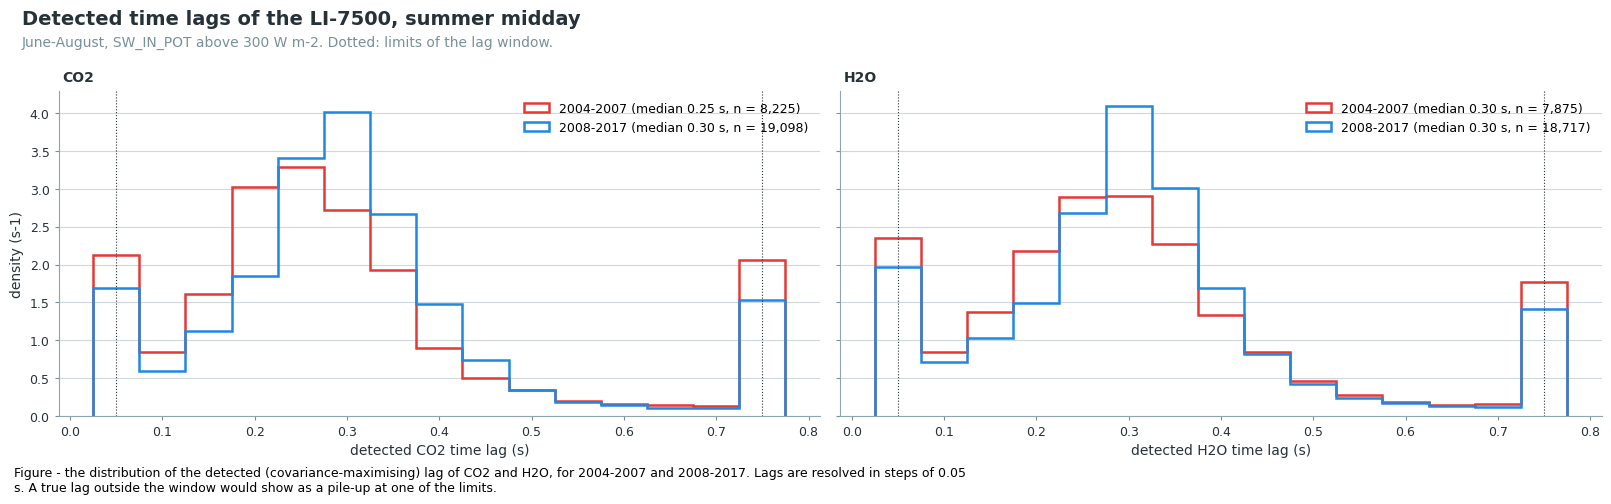

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True, layout='constrained')
_edges = np.arange(0.025, 0.80, 0.05)   # the lags are multiples of 0.05 s (20 Hz)
for _ax, _gas in zip(axs, ('CO2', 'H2O')):
    for _g, _color in GROUP_COLORS.items():
        _x = _m.loc[_m['group'] == _g, f'{_gas}_TLAG_ACTUAL'].dropna()
        _ax.hist(_x, bins=_edges, density=True, histtype='step', linewidth=1.8, color=_color,
                 label=f"{_g} (median {_x.median():.2f} s, n = {len(_x):,})")
    for _v in (0.05, 0.75):
        _ax.axvline(_v, color=cp.INK, linewidth=0.8, linestyle=':')
    _ax.set_xlabel(f'detected {_gas} time lag (s)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, f'{_gas}')
    _ax.legend(frameon=False, fontsize=9, loc='upper right')
axs[0].set_ylabel('density (s-1)')
cp.figure_title(fig, 'Detected time lags of the LI-7500, summer midday',
                'June-August, SW_IN_POT above 300 W m-2. Dotted: limits of the lag window.')
figcap(fig, "the distribution of the detected (covariance-maximising) lag of CO2 and H2O, for 2004-2007 and "
            "2008-2017. Lags are resolved in steps of 0.05 s. A true lag outside the window would show as a pile-up "
            "at one of the limits.")
plt.show()

### 📊 Plot: detected CO2 time lag by wind direction, per year

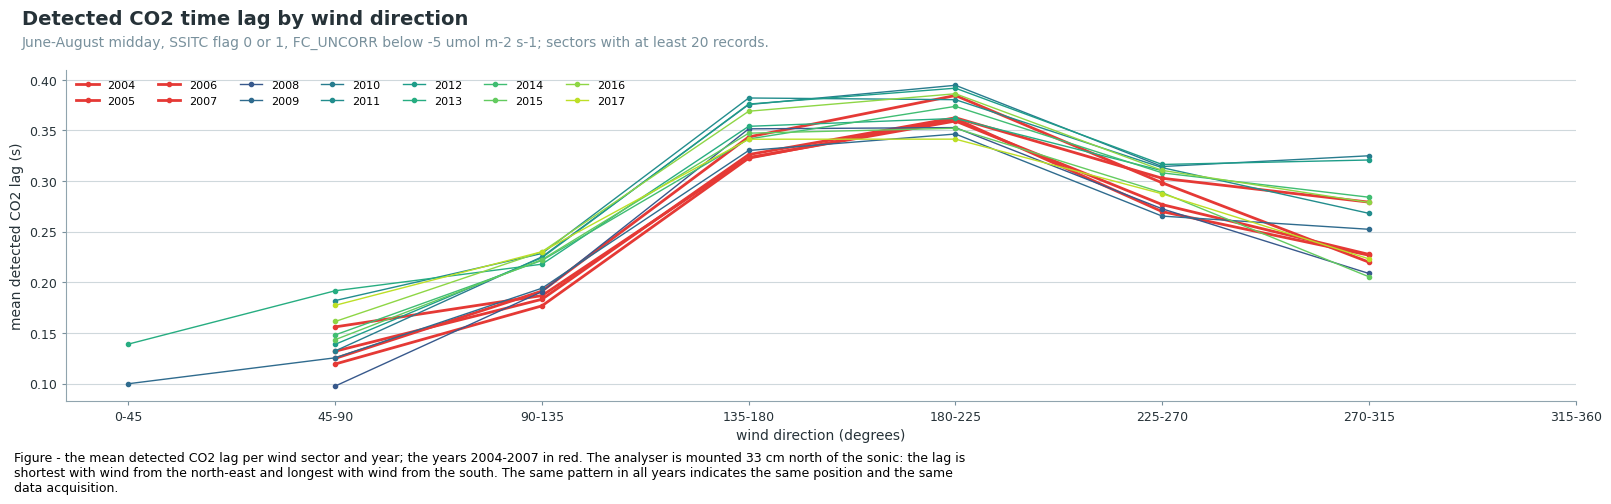

In [12]:
_wd_edges = np.arange(0, 361, 45)
_s = _m[(_m['FC_SSITC_TEST'] <= 1) & (_m['FC_UNCORR'] < -5)]
_gl = _s.groupby(['year', pd.cut(_s['WD'], _wd_edges)], observed=False)['CO2_TLAG_ACTUAL']
LAG_WD = _gl.mean().where(_gl.size() >= 20).unstack()
fig, ax = plt.subplots(figsize=(16, 5), layout='constrained')
_x = np.arange(len(_wd_edges) - 1)
_years = LAG_WD.index
_shades = plt.get_cmap('viridis')(np.linspace(0, 0.9, len(_years)))
for _y, _color in zip(_years, _shades):
    _early = EARLY[0] <= _y <= EARLY[1]
    ax.plot(_x, LAG_WD.loc[_y].to_numpy(), color=cp.TEST_COLORS[0] if _early else _color,
            linewidth=2.0 if _early else 1.0, marker='o', markersize=3, label=str(_y))
ax.set_xticks(_x, [f"{a}-{b}" for a, b in zip(_wd_edges[:-1], _wd_edges[1:])])
ax.set_xlabel('wind direction (degrees)')
ax.set_ylabel('mean detected CO2 lag (s)')
cp.style_axes(ax)
ax.legend(frameon=False, fontsize=8, ncol=7, loc='upper left')
cp.figure_title(fig, 'Detected CO2 time lag by wind direction',
                'June-August midday, SSITC flag 0 or 1, FC_UNCORR below -5 umol m-2 s-1; sectors with at least 20 records.')
figcap(fig, "the mean detected CO2 lag per wind sector and year; the years 2004-2007 in red. The analyser is "
            "mounted 33 cm north of the sonic: the lag is shortest with wind from the north-east and longest with "
            "wind from the south. The same pattern in all years indicates the same position and the same data "
            "acquisition.")
plt.show()

### 📋 Table: correlation of w and H2O with and without a detected lag at a window limit

Records whose detected lag lies at a limit received the nominal lag. Their H2O correlation
coefficient, standardised to the same stability and u* (see section 5), is compared with that of
the other records of the same group of years. The difference, times the extra share of records at
a limit in 2004-2007, bounds the loss that the lag detection can cause there. The bound is
generous: records with a weak flux are also those where the lag is hardest to detect.

In [13]:
# Selection and fixed distribution of stability and u* for the correlation coefficients (section 5).
def corr_selection(d):
    return d[d['midsummer'] & (d['FC_SSITC_TEST'] <= 1) & (d['LE_SSITC_TEST'] <= 1) & (d['H_SSITC_TEST'] <= 1)
             & (d['ZL'] < 0) & (d['USTAR'] > USTAR_BINS[0]) & (d['H'] > MIN_H)].copy()


SA, SB = corr_selection(A), corr_selection(B)
_pool = pd.concat([SA, SB])
W_STAB = _pool.groupby([pd.cut(_pool['ZL'], ZL_BINS), pd.cut(_pool['USTAR'], USTAR_BINS)], observed=True).size()
W_STAB = W_STAB / W_STAB.sum()


def std_r(d, col):
    """Median of col per cell of z/L and u*, averaged with the fixed weights W_STAB."""
    g = d.groupby([pd.cut(d['ZL'], ZL_BINS), pd.cut(d['USTAR'], USTAR_BINS)], observed=True)[col]
    m = g.median()[g.size() >= MIN_CELL_N]
    w = W_STAB.reindex(m.index).fillna(0)
    return (m * w).sum() / w.sum() if w.sum() > 0 else np.nan


SA['h2o_lag_at_limit'] = (np.isclose(SA['H2O_TLAG_ACTUAL'], SA['H2O_TLAG_MIN'])
                          | np.isclose(SA['H2O_TLAG_ACTUAL'], SA['H2O_TLAG_MAX']))
_rows = {}
for _g, _d in SA.groupby('group'):
    _at, _free = _d[_d['h2o_lag_at_limit']], _d[~_d['h2o_lag_at_limit']]
    _rows[_g] = {'records at a limit': len(_at), 'r_wq at a limit': std_r(_at, 'r_wq'),
                 'records not at a limit': len(_free), 'r_wq not at a limit': std_r(_free, 'r_wq'),
                 'share at a limit %': 100 * _d['h2o_lag_at_limit'].mean()}
LAG_LOSS = pd.DataFrame(_rows).T
LAG_LOSS['relative loss at a limit'] = 1 - LAG_LOSS['r_wq at a limit'] / LAG_LOSS['r_wq not at a limit']
_extra = (LAG_LOSS.loc[G_EARLY, 'share at a limit %'] - LAG_LOSS.loc[G_REF, 'share at a limit %']) / 100
LAG_BOUND = _extra * LAG_LOSS.loc[G_REF, 'relative loss at a limit']
tabcap("per group of years, the summer midday records of the correlation selection (section 5) split by whether "
       "the detected H2O lag lies at a window limit: their number, their standardised correlation of w and H2O, "
       "the share at a limit, and the relative loss of correlation at a limit")
display(LAG_LOSS.round(3))
print(f"Extra share at a limit in {G_EARLY}: {100 * _extra:+.1f} percentage points; bound of the covariance loss "
      f"from the lag detection: {100 * LAG_BOUND:.1f} %")

Table - per group of years, the summer midday records of the correlation selection (section 5) split
by whether the detected H2O lag lies at a window limit: their number, their standardised correlation
of w and H2O, the share at a limit, and the relative loss of correlation at a limit



,records at a limit,r_wq at a limit,records not at a limit,r_wq not at a limit,share at a limit %,relative loss at a limit
2004-2007,497.0,0.341,4517.0,0.423,9.912,0.195
2008-2017,896.0,0.337,11370.0,0.439,7.305,0.233


Extra share at a limit in 2004-2007: +2.6 percentage points; bound of the covariance loss from the lag detection: 0.6 %


## 🩺 3 Analyser diagnostics

The automatic gain control (AGC) of the LI-7500 rises when the optical path is obstructed, by dirt,
water or ice. EddyPro reports it as `CUSTOM_AGC_IRGA75_MEAN`, in steps of 6.25 %. The column
`INST_LI7500_AGC_OR_RSSI` holds only its missing-value code.

### 📊 Plot: AGC of the LI-7500 per month

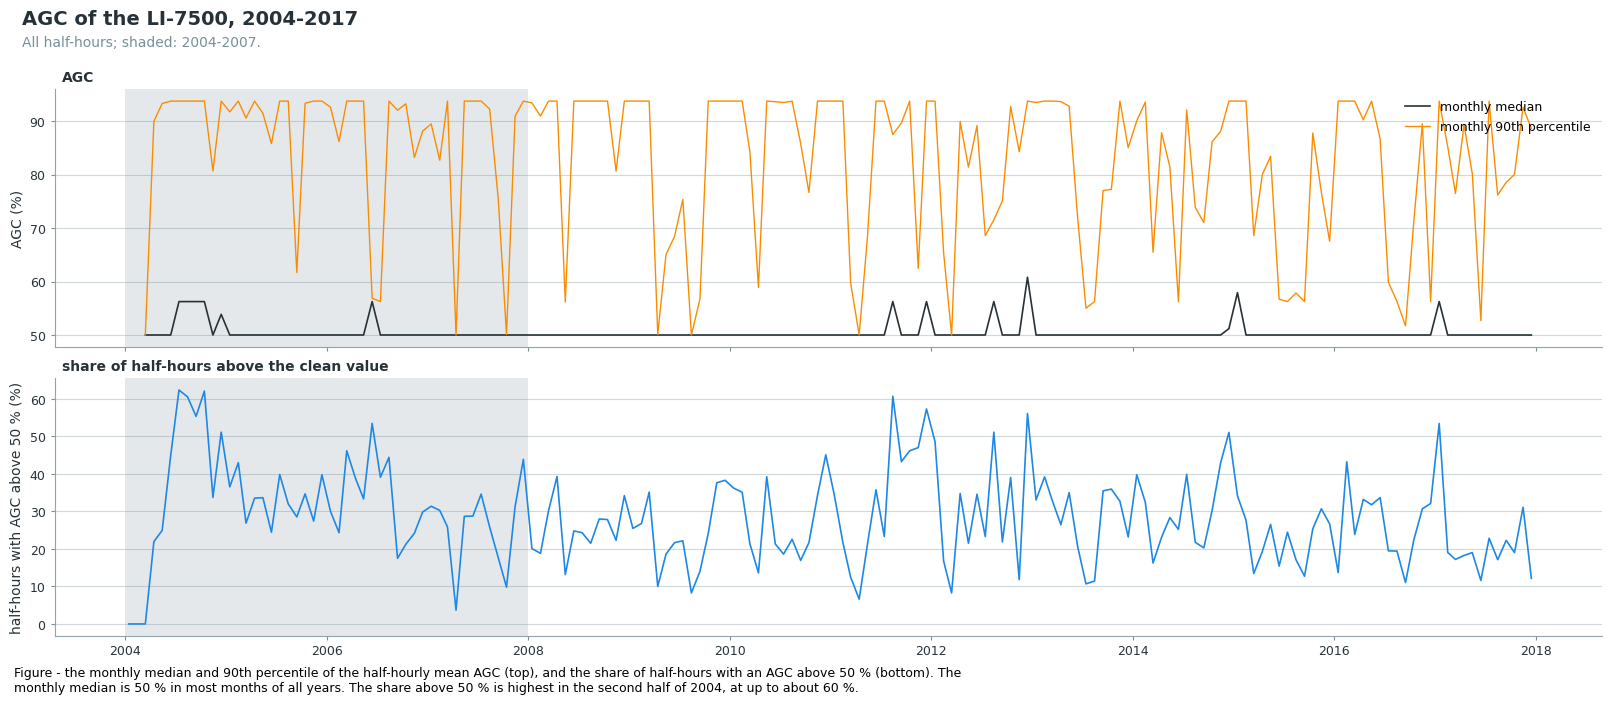

In [14]:
_agc = A['CUSTOM_AGC_IRGA75_MEAN'].where(A['CUSTOM_AGC_IRGA75_MEAN'].between(0, 100))
_mon = _agc.groupby(A.index.to_period('M'))
AGC_M = pd.DataFrame({'median': _mon.median(), 'p90': _mon.quantile(0.9),
                      'share above 50 %': _mon.apply(lambda s: 100 * (s > 50.1).mean())})
AGC_M.index = AGC_M.index.to_timestamp() + pd.Timedelta('14D')
fig, axs = plt.subplots(2, 1, figsize=(16, 7), sharex=True, layout='constrained')
axs[0].plot(AGC_M.index, AGC_M['median'], color=cp.INK, linewidth=1.2, label='monthly median')
axs[0].plot(AGC_M.index, AGC_M['p90'], color=cp.TEST_COLORS[1], linewidth=1.0, label='monthly 90th percentile')
axs[0].set_ylabel('AGC (%)')
axs[1].plot(AGC_M.index, AGC_M['share above 50 %'], color=cp.TEST_COLORS[3], linewidth=1.2)
axs[1].set_ylabel('half-hours with AGC above 50 % (%)')
for _ax in axs:
    _ax.axvspan(pd.Timestamp(f'{EARLY[0]}-01-01'), pd.Timestamp(f'{EARLY[1]}-12-31'), color=cp.MUTED, alpha=0.2,
                linewidth=0)
    cp.style_axes(_ax)
axs[0].legend(frameon=False, fontsize=9, loc='upper right')
cp.panel_label(axs[0], 'AGC')
cp.panel_label(axs[1], 'share of half-hours above the clean value')
cp.figure_title(fig, 'AGC of the LI-7500, 2004-2017', 'All half-hours; shaded: 2004-2007.')
figcap(fig, "the monthly median and 90th percentile of the half-hourly mean AGC (top), and the share of half-hours "
            "with an AGC above 50 % (bottom). The monthly median is 50 % in most months of all years. The share "
            "above 50 % is highest in the second half of 2004, at up to about 60 %.")
plt.show()

### 📋 Table: analyser diagnostics per year, summer midday

In [15]:
_g = _m.groupby('year')
DIAG = pd.DataFrame({'AGC median %': _g['CUSTOM_AGC_IRGA75_MEAN'].median(),
                     'AGC above 50 %': _g['CUSTOM_AGC_IRGA75_MEAN'].apply(lambda s: 100 * (s > 50.1).mean()),
                     'status code median': _g['CUSTOM_STATUS_CODE_IRGA75_MEAN'].median(),
                     'CO2 records per half-hour': _g['CO2_NR'].median()})
tabcap("per year, June-August with SW_IN_POT above 300 W m-2: the median AGC, the share of half-hours with an "
       "AGC above 50 %, the median of the half-hourly mean status code of the LI-7500 data stream "
       "(CUSTOM_STATUS_CODE_IRGA75_MEAN; its coding is not documented in this repository), and the median number "
       "of valid CO2 records per half-hour (36,000 at 20 Hz)")
display(DIAG.round(2))

Table - per year, June-August with SW_IN_POT above 300 W m-2: the median AGC, the share of half-
hours with an AGC above 50 %, the median of the half-hourly mean status code of the LI-7500 data
stream (CUSTOM_STATUS_CODE_IRGA75_MEAN; its coding is not documented in this repository), and the
median number of valid CO2 records per half-hour (36,000 at 20 Hz)



,AGC median %,AGC above 50 %,status code median,CO2 records per half-hour
year,,,,
2004,56.25,60.91,3.96,36000.0
2005,50.00,35.80,4.10,36000.0
2006,50.91,51.73,3.89,36000.0
2007,50.00,28.52,3.94,36000.0
2008,50.00,22.70,4.06,36000.0
2009,50.00,16.08,3.91,36000.0
2010,50.00,25.12,0.00,36000.0
2011,50.03,41.06,0.46,35963.0
2012,50.00,38.25,0.88,35955.0


### 📋 Table: correlation coefficients by AGC class, summer midday

In [16]:
SA['agc_class'] = np.where(SA['CUSTOM_AGC_IRGA75_MEAN'] > 50.1, 'AGC above 50 %', 'AGC 50 %')
_rows = {}
for (_g, _c), _d in SA.groupby(['group', 'agc_class']):
    _rows[(_g, _c)] = {'records': len(_d), **{_r: std_r(_d, _r) for _r in ('r_wT', 'r_wc', 'r_wq')}}
AGC_R = pd.DataFrame(_rows).T
tabcap("per group of years and AGC class, the number of records and the correlation coefficients of w with sonic "
       "temperature, CO2 and H2O, standardised to the same distribution of stability and u* (section 5)")
display(AGC_R.round(3))
_share = SA.groupby('year')['agc_class'].apply(lambda s: (s != 'AGC 50 %').mean())
_loss = 1 - AGC_R.loc[(G_REF, 'AGC above 50 %'), 'r_wq'] / AGC_R.loc[(G_REF, 'AGC 50 %'), 'r_wq']
_extra_agc = _share[_share.index.map(group_of) == G_EARLY].mean() - _share[_share.index.map(group_of) == G_REF].mean()
AGC_BOUND = _extra_agc * _loss
print(f"Records with AGC above 50 %: {100 * _share[_share.index.map(group_of) == G_EARLY].mean():.0f} % in {G_EARLY}, "
      f"{100 * _share[_share.index.map(group_of) == G_REF].mean():.0f} % in {G_REF}; their H2O correlation is "
      f"{100 * _loss:.1f} % lower in {G_REF}. The extra share accounts for {100 * AGC_BOUND:.1f} % of the "
      f"correlation of {G_EARLY}.")

Table - per group of years and AGC class, the number of records and the correlation coefficients of
w with sonic temperature, CO2 and H2O, standardised to the same distribution of stability and u*
(section 5)



records   r_wT   r_wc   r_wq
2004-2007 AGC 50 %         3517.0  0.515  0.477  0.429
          AGC above 50 %   1497.0  0.502  0.428  0.385
2008-2017 AGC 50 %        10575.0  0.502  0.493  0.439
          AGC above 50 %   1691.0  0.507  0.438  0.394

Records with AGC above 50 %: 29 % in 2004-2007, 14 % in 2008-2017; their H2O correlation is 10.1 % lower in 2008-2017. The extra share accounts for 1.5 % of the correlation of 2004-2007.


## 🧪 4 Concentration readings

**CO2.** The summer midday median of the CO2 mixing ratio of the LI-7500 is compared with a linear
trend fitted to the years 2008-2017, after the recalibration of December 2007. The ratio of the
two estimates the gain of the analyser before the recalibration. An error of the span scales the
flux in proportion; an error of the zero changes it by a few per cent at most.

**H2O.** The water vapour density of the LI-7500 is compared with the density computed from the
relative humidity and air temperature of the meteo station at the same height, over the years of
one humidity probe (2005-2015). The slope of a regression of the analyser density on the probe
density, per year and relative to the median slope of 2008-2015, estimates the change of the
H2O gain. The absolute level of the two densities differs by about 30 % in all years; this offset
is the same in every year and is not examined here.

In [17]:
_co2 = A[A['month'].isin(SUMMER) & (A.index.hour >= 11) & (A.index.hour <= 15)]
_co2y = _co2.groupby('year')['CO2_MIXING_RATIO'].median()
_fit = np.polyfit(_co2y.loc[REF75[0]:REF75[1]].index, _co2y.loc[REF75[0]:REF75[1]].to_numpy(), 1)
CONC = pd.DataFrame({'CO2 median (umol mol-1)': _co2y, 'CO2 trend (umol mol-1)': np.polyval(_fit, _co2y.index)})
CONC['CO2 gain'] = CONC['CO2 median (umol mol-1)'] / CONC['CO2 trend (umol mol-1)']

# Vapour density from the probe (Magnus formula over water), mmol m-3.
_es = 611.2 * np.exp(17.62 * A['ta'] / (243.12 + A['ta']))
A['rhov_probe'] = A['rh'] / 100 * _es / (8.314 * (A['ta'] + 273.15)) * 1000
_h = A[(A['SW_IN_POT'] > 0) & (A['ta_flag'] == 0) & A['rh'].between(20, 90) & A['H2O_MOLAR_DENSITY'].notna()
       & (A['year'] >= H2O_CHECK_YEARS[0]) & (A['year'] <= H2O_CHECK_YEARS[1])]
_slope = _h.groupby('year').apply(lambda q: np.polyfit(q['rhov_probe'], q['H2O_MOLAR_DENSITY'], 1)[0])
_ratio = _h.groupby('year').apply(lambda q: (q['H2O_MOLAR_DENSITY'] / q['rhov_probe']).median())
CONC['H2O density ratio analyser / probe'] = _ratio
CONC['H2O slope analyser / probe'] = _slope
CONC['H2O gain'] = _slope / _slope.loc[REF75[0]:H2O_CHECK_YEARS[1]].median()
GAIN_CO2 = CONC['CO2 gain'].where(CONC.index <= EARLY[1], 1.0).clip(upper=1.0)
GAIN_H2O = CONC['H2O gain']
print(f"CO2 trend of {REF75[0]}-{REF75[1]}: {_fit[0]:.2f} umol mol-1 per year")

CO2 trend of 2008-2017: 2.11 umol mol-1 per year


### 📋 Table: CO2 and H2O readings of the LI-7500 and the implied gain, per year

In [18]:
tabcap("per year: the median CO2 mixing ratio of May-September, 11 to 16 h; the linear trend of 2008-2017 at that "
       "year; their ratio (CO2 gain); the median ratio of the LI-7500 water vapour density to that of the "
       "humidity probe and the slope of a regression of the one on the other, daytime half-hours with measured "
       "air temperature and RH of 20 to 90 %; and the slope relative to the median slope of 2008-2015 (H2O "
       "gain). The H2O columns are empty outside 2005-2015")
display(CONC.round(3))

Table - per year: the median CO2 mixing ratio of May-September, 11 to 16 h; the linear trend of
2008-2017 at that year; their ratio (CO2 gain); the median ratio of the LI-7500 water vapour density
to that of the humidity probe and the slope of a regression of the one on the other, daytime half-
hours with measured air temperature and RH of 20 to 90 %; and the slope relative to the median slope
of 2008-2015 (H2O gain). The H2O columns are empty outside 2005-2015



,CO2 median (umol mol-1),CO2 trend (umol mol-1),CO2 gain,H2O density ratio analyser / probe,H2O slope analyser / probe,H2O gain
year,,,,,,
2004,368.847,374.720,0.984,NaN,NaN,NaN
2005,369.599,376.831,0.981,1.261,1.251,0.962
2006,355.938,378.942,0.939,1.282,1.278,0.983
2007,358.066,381.053,0.940,1.283,1.275,0.980
2008,380.639,383.164,0.993,1.298,1.309,1.006
2009,386.108,385.274,1.002,1.297,1.297,0.997
2010,392.806,387.385,1.014,1.300,1.304,1.003
2011,388.751,389.496,0.998,1.292,1.284,0.987
2012,390.446,391.607,0.997,1.305,1.283,0.986


## 🔗 5 Correlation coefficients at matched stability

For each summer midday record (June-August, `SW_IN_POT` above 300 W m-2, SSITC flag 0 or 1 for
`FC`, `LE` and `H`, unstable stratification, u* above 0.2 m s-1, `H` above 20 W m-2), the
correlation coefficient of the vertical wind with sonic temperature (`r_wT`), CO2 (`r_wc`) and H2O
(`r_wq`) is computed from the covariances and standard deviations of the EddyPro output, together
with that of CO2 with H2O (`r_cq`). Per year, the median is taken in cells of z/L and u* and
averaged with the distribution of all records of both analysers over these cells, so that the
years differ only by what they measured under the same turbulence.

**How to read it.** A damping of the gas covariances by the analyser or the lag detection lowers
`r_wc` and `r_wq` by the damping factor and leaves `r_wT` unchanged. A smaller ecosystem flux
does not change the correlation (flux-variance similarity). Noise in the gas signals lowers `r_wc`,
`r_wq` and also `r_cq`; the time lag does not affect `r_cq`, since both gases are measured in the
same path. For the LI-7500 the covariances are those of the gas densities, before the WPL
correction, and `r_wc` includes the self-heating of the analyser.

The LI-7200 years 2016-2025 show the year-to-year spread with a stable instrument. Their level
differs from the LI-7500: the LI-7200 measures mole fractions, without density fluctuations, and
its intake tube damps H2O.

In [19]:
_rows = {}
for _name, _d in (('IRGA75', SA), ('IRGA72', SB)):
    for _y, _g in _d.groupby('year'):
        _rows[(_name, _y)] = {'records': len(_g), **{_r: std_r(_g, _r) for _r in ('r_wT', 'r_wc', 'r_wq', 'r_cq')}}
CORR = pd.DataFrame(_rows).T
CORR.index.names = ['analyser', 'year']
CORR['r_wc / r_wT'] = CORR['r_wc'] / CORR['r_wT']
CORR['r_wq / r_wT'] = CORR['r_wq'] / CORR['r_wT']
_swc = met.loc[met.index.month.isin(MIDSUMMER), 'swc30']
CORR['SWC 0.3 m (%)'] = [_swc[_swc.index.year == _y].mean() for _y in CORR.index.get_level_values('year')]

_c75 = CORR.loc['IRGA75']
_ref = _c75.loc[REF75[0]:REF75[1]]
REF_R = _ref[['r_wT', 'r_wc', 'r_wq', 'r_cq']].mean()
REL = (_c75[['r_wT', 'r_wc', 'r_wq', 'r_cq']] / REF_R)
_c72 = CORR.loc['IRGA72']
_wet72 = _c72.drop(index=list(DRY72))
SPREAD72 = (_c72[['r_wT', 'r_wc', 'r_wq', 'r_cq']] / _c72[['r_wT', 'r_wc', 'r_wq', 'r_cq']].mean()).std()
DRY_EFFECT72 = _c72.loc[list(DRY72), ['r_wc', 'r_wq', 'r_cq']] / _wet72[['r_wc', 'r_wq', 'r_cq']].mean()

### 📋 Table: correlation coefficients per year at matched stability and u*, both analysers

In [20]:
tabcap("per analyser and year, the number of summer midday records and the standardised correlation coefficients "
       "of w with sonic temperature (r_wT), CO2 (r_wc) and H2O (r_wq), of CO2 with H2O (r_cq), the ratios of the "
       "gas correlations to r_wT, and the mean June-August soil water content at 0.3 m. Signs are chosen so that "
       "all coefficients are positive in summer daytime")
display(CORR.round(3))

Table - per analyser and year, the number of summer midday records and the standardised correlation
coefficients of w with sonic temperature (r_wT), CO2 (r_wc) and H2O (r_wq), of CO2 with H2O (r_cq),
the ratios of the gas correlations to r_wT, and the mean June-August soil water content at 0.3 m.
Signs are chosen so that all coefficients are positive in summer daytime



records   r_wT   r_wc   r_wq   r_cq  r_wc / r_wT  r_wq / r_wT  SWC 0.3 m (%)
analyser year                                                                              
IRGA75   2004   1261.0  0.517  0.455  0.411  0.698        0.880        0.794            NaN
         2005   1315.0  0.514  0.463  0.414  0.700        0.900        0.806         22.472
         2006   1275.0  0.497  0.470  0.406  0.677        0.946        0.817         20.708
         2007   1163.0  0.514  0.479  0.436  0.720        0.933        0.849         25.811
         2008   1286.0  0.520  0.481  0.440  0.748        0.926        0.847         24.209
         2009   1358.0  0.509  0.485  0.432  0.738        0.952        0.848         23.872
         2010   1019.0  0.507  0.505  0.427  0.778        0.996        0.841         26.510
         2011   1139.0  0.516  0.496  0.438  0.716        0.961        0.849         25.473
         2012   1063.0  0.501  0.486  0.442  0.768        0.970        0.882         25.244
         2013   1079.0  0.491  0.491  0.417  0.752        1.000        0.849         23.855
         2014   1250.0  0.496  0.486  0.432  0.749        0.981        0.871         26.360
         2015   1386.0  0.496  0.476  0.416  0.661        0.959        0.838         24.433
         2016   1283.0  0.503  0.500  0.461  0.738        0.994        0.916         27.056
         2017   1403.0  0.487  0.482  0.441  0.713        0.988        0.905         22.419
IRGA72   2016   1345.0  0.497  0.432  0.474  0.641        0.871        0.955         27.056
         2017   1386.0  0.485  0.388  0.450  0.565        0.801        0.929         22.419
         2018   1351.0  0.476  0.399  0.434  0.573        0.839        0.913         21.642
         2019   1421.0  0.475  0.418  0.444  0.664        0.879        0.934         22.960
         2020   1400.0  0.487  0.393  0.436  0.564        0.807        0.895         26.478
         2021   1297.0  0.491  0.421  0.451  0.657        0.857        0.918         26.138
         2022   1521.0  0.482  0.369  0.413  0.500        0.765        0.856         21.764
         2023   1386.0  0.480  0.409  0.446  0.624        0.852        0.929         22.277
         2024   1315.0  0.499  0.437  0.465  0.618        0.875        0.931            NaN
         2025   1409.0  0.481  0.428  0.442  0.684        0.890        0.920         24.171

### 📋 Table: correlation coefficients of the LI-7500 relative to 2008-2017

In [21]:
tabcap("per year, the standardised correlation coefficients of the LI-7500 divided by their mean over 2008-2017. "
       "The last rows give, for comparison, the relative year-to-year standard deviation of the LI-7200 years "
       "2016-2025, and the dry LI-7200 summers 2018 and 2022 relative to the mean of the other LI-7200 years")
_cmp = pd.concat([REL.round(3),
                  SPREAD72.rename('IRGA72: relative sd of years').to_frame().T.round(3),
                  DRY_EFFECT72.rename(index=lambda y: f'IRGA72 {y} / other years').round(3)])
display(_cmp)

Table - per year, the standardised correlation coefficients of the LI-7500 divided by their mean
over 2008-2017. The last rows give, for comparison, the relative year-to-year standard deviation of
the LI-7200 years 2016-2025, and the dry LI-7200 summers 2018 and 2022 relative to the mean of the
other LI-7200 years



,r_wT,r_wc,r_wq,r_cq
2004,1.029,0.932,0.946,0.948
2005,1.023,0.946,0.954,0.951
2006,0.989,0.962,0.935,0.920
2007,1.022,0.981,1.004,0.978
2008,1.034,0.984,1.013,1.016
2009,1.013,0.992,0.994,1.003
2010,1.009,1.034,0.982,1.056
2011,1.026,1.014,1.008,0.972
2012,0.997,0.994,1.018,1.043
2013,0.977,1.004,0.960,1.022


### 📊 Plot: correlation coefficients per year at matched stability and u*

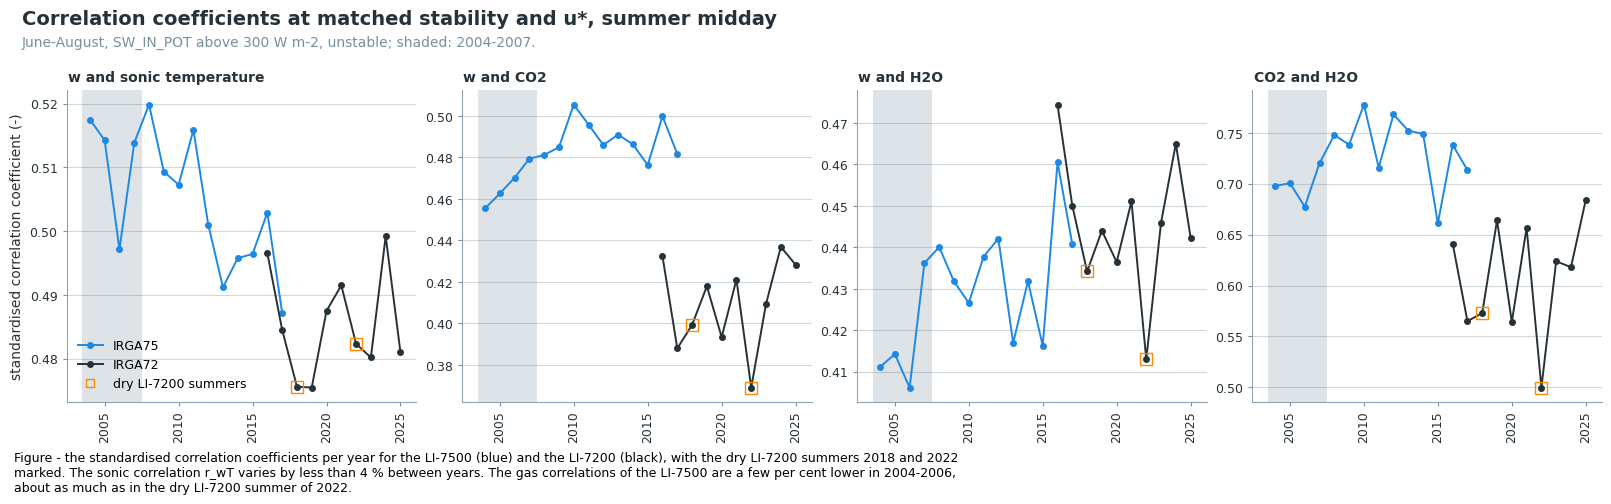

In [22]:
fig, axs = plt.subplots(1, 4, figsize=(16, 5), sharex=True, layout='constrained')
for _ax, _r, _title in zip(axs, ('r_wT', 'r_wc', 'r_wq', 'r_cq'),
                           ('w and sonic temperature', 'w and CO2', 'w and H2O', 'CO2 and H2O')):
    for _name, _color in (('IRGA75', cp.TEST_COLORS[3]), ('IRGA72', cp.INK)):
        _v = CORR.loc[_name, _r]
        _ax.plot(_v.index, _v.to_numpy(), color=_color, marker='o', markersize=4, linewidth=1.4, label=_name)
    _ax.axvspan(EARLY[0] - 0.5, EARLY[1] + 0.5, color=cp.MUTED, alpha=0.25, linewidth=0)
    for _y in DRY72:
        _ax.plot(_y, CORR.loc[('IRGA72', _y), _r], marker='s', markersize=8, markerfacecolor='none',
                 color=cp.TEST_COLORS[1], linestyle='none')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
    _ax.tick_params(axis='x', labelrotation=90)
axs[0].plot([], [], marker='s', markerfacecolor='none', color=cp.TEST_COLORS[1], linestyle='none',
            label='dry LI-7200 summers')
axs[0].legend(frameon=False, fontsize=9, loc='lower left')
axs[0].set_ylabel('standardised correlation coefficient (-)')
cp.figure_title(fig, 'Correlation coefficients at matched stability and u*, summer midday',
                'June-August, SW_IN_POT above 300 W m-2, unstable; shaded: 2004-2007.')
figcap(fig, "the standardised correlation coefficients per year for the LI-7500 (blue) and the LI-7200 (black), "
            "with the dry LI-7200 summers 2018 and 2022 marked. The sonic correlation r_wT varies by less than "
            "4 % between years. The gas correlations of the LI-7500 are a few per cent lower in 2004-2006, about as much as "
            "in the dry LI-7200 summer of 2022.")
plt.show()

### 📊 Plot: correlation of w and the gases against soil water content

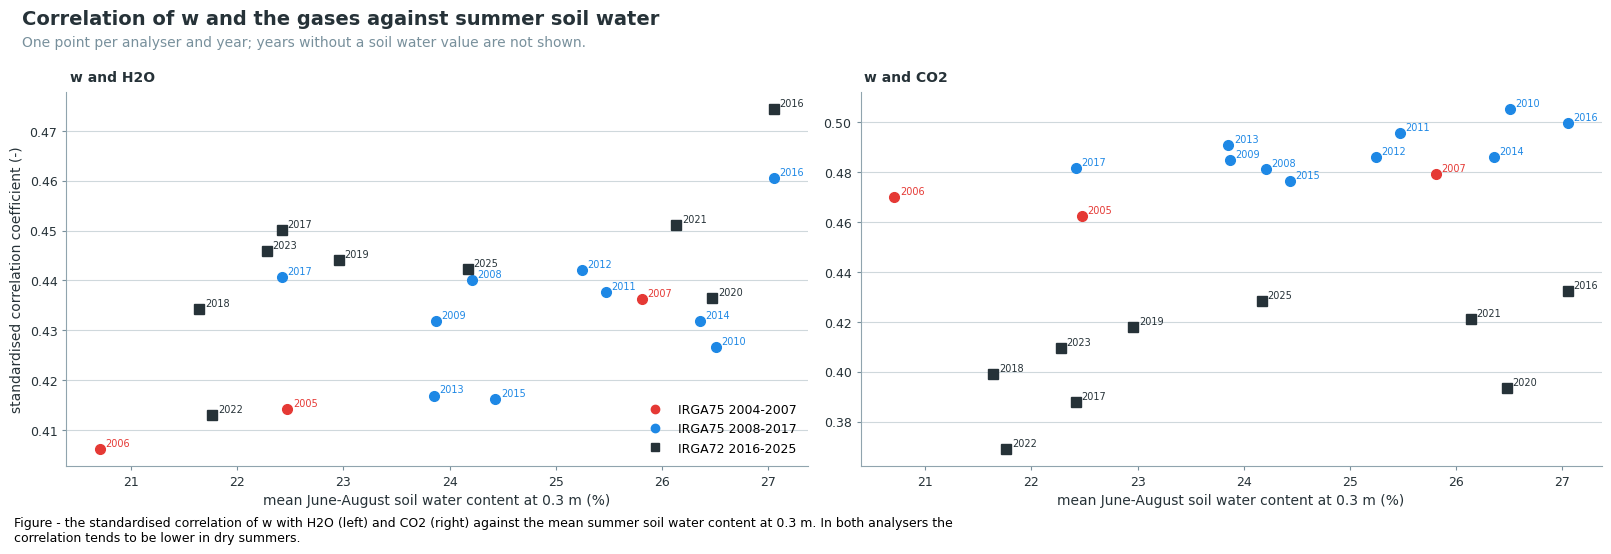

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), layout='constrained')
for _ax, _r, _title in zip(axs, ('r_wq', 'r_wc'), ('w and H2O', 'w and CO2')):
    for _name, _marker in (('IRGA75', 'o'), ('IRGA72', 's')):
        _c = CORR.loc[_name]
        for _y, _row in _c.dropna(subset=['SWC 0.3 m (%)']).iterrows():
            _early = _name == 'IRGA75' and EARLY[0] <= _y <= EARLY[1]
            _color = cp.TEST_COLORS[0] if _early else (cp.TEST_COLORS[3] if _name == 'IRGA75' else cp.INK)
            _ax.plot(_row['SWC 0.3 m (%)'], _row[_r], marker=_marker, color=_color, markersize=7, linestyle='none')
            _ax.annotate(str(_y), (_row['SWC 0.3 m (%)'], _row[_r]), fontsize=7, xytext=(4, 2),
                         textcoords='offset points', color=_color)
    _ax.set_xlabel('mean June-August soil water content at 0.3 m (%)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('standardised correlation coefficient (-)')
axs[0].plot([], [], 'o', color=cp.TEST_COLORS[0], label='IRGA75 2004-2007')
axs[0].plot([], [], 'o', color=cp.TEST_COLORS[3], label='IRGA75 2008-2017')
axs[0].plot([], [], 's', color=cp.INK, label='IRGA72 2016-2025')
axs[0].legend(frameon=False, fontsize=9, loc='lower right')
cp.figure_title(fig, 'Correlation of w and the gases against summer soil water',
                'One point per analyser and year; years without a soil water value are not shown.')
figcap(fig, "the standardised correlation of w with H2O (left) and CO2 (right) against the mean summer soil water "
            "content at 0.3 m. In both analysers the correlation tends to be lower in dry summers.")
plt.show()

## ⚖️ 6 Energy balance

A damping of the H2O covariance lowers `LE` relative to the available energy, while `H` from the
sonic is unaffected. Per year, the ratios are formed from sums over the June-August midday records
with measured radiation and SSITC flag 0 or 1 for `LE` and `H`. Rn is computed from the four
radiation components; the ground heat flux and the storage in the canopy are not included.

### 📋 Table: LE and H relative to the available energy, per year, summer midday

In [24]:
def energy_table(d):
    s = d[d['midsummer'] & d['sw_meas'] & (d['LE_SSITC_TEST'] <= 1) & (d['H_SSITC_TEST'] <= 1)].dropna(
        subset=['LE', 'H', 'rn'])
    g = s.groupby('year')
    return pd.DataFrame({'records': g.size(),
                         'LE / (Rn - H)': g.apply(lambda q: q['LE'].sum() / (q['rn'] - q['H']).sum()),
                         'H / Rn': g.apply(lambda q: q['H'].sum() / q['rn'].sum()),
                         '(H + LE) / Rn': g.apply(lambda q: (q['H'] + q['LE']).sum() / q['rn'].sum()),
                         'Rn / SW_IN': g.apply(lambda q: q['rn'].sum() / q['sw'].sum()),
                         'median FH2O (mmol m-2 s-1)': g['FH2O'].median()})


ENERGY = pd.concat({'IRGA75': energy_table(A), 'IRGA72': energy_table(B)}, names=['analyser'])
ENERGY = ENERGY[ENERGY['records'] > 500]
tabcap("per analyser and year, June-August, SW_IN_POT above 300 W m-2, measured SW_IN, LE and H with SSITC flag 0 "
       "or 1: LE relative to the available energy Rn - H, H and H + LE relative to Rn (ratios of sums), Rn "
       "relative to SW_IN, and the median H2O flux. Years with fewer than 500 such records (before the radiation "
       "measurements of September 2005) are left out")
display(ENERGY.round(3))
_e = ENERGY.loc['IRGA75', 'LE / (Rn - H)']
print(f"LE / (Rn - H): {_e.loc[2006]:.2f} (2006) and {_e.loc[2007]:.2f} (2007); 2008-2010: "
      f"{_e.loc[2008]:.2f} to {_e.loc[2010]:.2f}; 2011-2017: {_e.loc[2011:2017].min():.2f} to "
      f"{_e.loc[2011:2017].max():.2f} (mean {_e.loc[2011:2017].mean():.2f})")

Table - per analyser and year, June-August, SW_IN_POT above 300 W m-2, measured SW_IN, LE and H with
SSITC flag 0 or 1: LE relative to the available energy Rn - H, H and H + LE relative to Rn (ratios
of sums), Rn relative to SW_IN, and the median H2O flux. Years with fewer than 500 such records
(before the radiation measurements of September 2005) are left out



records  LE / (Rn - H)  H / Rn  (H + LE) / Rn  Rn / SW_IN  median FH2O (mmol m-2 s-1)
analyser year                                                                                       
IRGA75   2006     1660          0.803   0.366          0.875       0.741                       3.892
         2007     1585          0.829   0.318          0.883       0.752                       4.443
         2008     1649          1.147   0.349          1.096       0.746                       5.754
         2009     1555          1.095   0.333          1.063       0.748                       5.634
         2010     1389          1.178   0.297          1.125       0.751                       5.961
         2011     1484          0.961   0.368          0.975       0.750                       4.637
         2012     1383          0.909   0.306          0.937       0.752                       5.055
         2013     1442          0.836   0.336          0.891       0.750                       4.098
         2014     1665          0.834   0.321          0.887       0.757                       4.417
         2015     1494          0.848   0.387          0.907       0.747                       4.564
         2016     1746          0.890   0.302          0.923       0.788                       5.301
         2017     1832          0.822   0.331          0.881       0.778                       4.737
IRGA72   2016     1888          0.806   0.305          0.865       0.790                       4.473
         2017     1914          0.814   0.335          0.877       0.780                       4.638
         2018     1767          0.738   0.394          0.841       0.768                       3.728
         2019     1907          0.761   0.319          0.837       0.764                       4.427
         2020     1879          0.830   0.391          0.897       0.774                       4.083
         2021     1874          0.812   0.311          0.870       0.775                       3.967
         2022     1990          0.843   0.459          0.915       0.751                       3.522
         2023     1896          0.818   0.360          0.883       0.767                       4.439
         2024     1857          0.840   0.313          0.890       0.789                       4.597
         2025     1862          0.806   0.307          0.866       0.778                       4.923

LE / (Rn - H): 0.80 (2006) and 0.83 (2007); 2008-2010: 1.15 to 1.18; 2011-2017: 0.82 to 0.96 (mean 0.87)


## 📉 7 Spectral correction and random uncertainty

EddyPro corrects the high-frequency losses of the LI-7500 with the method of Horst (1997), with a
spectral assessment from the data of each run. A change of the response of the analyser that the
assessment detects would show as a change of `FC_SCF` and `LE_SCF` relative to `H_SCF`.

### 📋 Table: spectral correction factors and relative random uncertainty per year, summer midday

In [25]:
_g = _m.groupby('year')
SPEC = pd.DataFrame({'FC_SCF': _g['FC_SCF'].median(), 'LE_SCF': _g['LE_SCF'].median(), 'H_SCF': _g['H_SCF'].median(),
                     'FC_RANDUNC_HF / |FC|': _g.apply(lambda q: (q['FC_RANDUNC_HF'] / q['FC'].abs()).median()),
                     'LE_RANDUNC_HF / |LE|': _g.apply(lambda q: (q['LE_RANDUNC_HF'] / q['LE'].abs()).median()),
                     'H_RANDUNC_HF / |H|': _g.apply(lambda q: (q['H_RANDUNC_HF'] / q['H'].abs()).median()),
                     'CO2_MEAS_SIGMA / CO2 density': _g.apply(lambda q: (q['CO2_MEAS_SIGMA'] / q['CO2_MOLAR_DENSITY']).median()),
                     'H2O_MEAS_SIGMA / H2O density': _g.apply(lambda q: (q['H2O_MEAS_SIGMA'] / q['H2O_MOLAR_DENSITY']).median())})
tabcap("per year, June-August with SW_IN_POT above 300 W m-2: the median spectral correction factor of FC, LE and "
       "H, the median random uncertainty (Finkelstein and Sims 2001) relative to the flux, and the median standard "
       "deviation of the CO2 and H2O densities relative to their mean")
display(SPEC.round(4))

Table - per year, June-August with SW_IN_POT above 300 W m-2: the median spectral correction factor
of FC, LE and H, the median random uncertainty (Finkelstein and Sims 2001) relative to the flux, and
the median standard deviation of the CO2 and H2O densities relative to their mean



,FC_SCF,LE_SCF,H_SCF,FC_RANDUNC_HF / |FC|,LE_RANDUNC_HF / |LE|,H_RANDUNC_HF / |H|,CO2_MEAS_SIGMA / CO2 density,H2O_MEAS_SIGMA / H2O density
year,,,,,,,,
2004,1.0259,1.0263,1.0204,0.3049,0.1836,0.1752,0.0044,0.0230
2005,1.0270,1.0278,1.0225,0.2946,0.1864,0.1806,0.0048,0.0245
2006,1.0281,1.0294,1.0235,0.2964,0.1863,0.1816,0.0048,0.0197
2007,1.0269,1.0284,1.0217,0.2837,0.1779,0.1884,0.0053,0.0218
2008,1.0274,1.0281,1.0226,0.2734,0.1732,0.1806,0.0050,0.0264
2009,1.0283,1.0288,1.0233,0.2671,0.1773,0.1827,0.0049,0.0272
2010,1.0289,1.0291,1.0243,0.2700,0.1835,0.1960,0.0051,0.0301
2011,1.0276,1.0279,1.0231,0.2666,0.1737,0.1724,0.0049,0.0231
2012,1.0265,1.0275,1.0220,0.2588,0.1759,0.1799,0.0052,0.0237


## 📐 8 Implied adjustment of the early summers

If the covariances measured by the LI-7500 are damped by a factor `d`, the raw covariance of CO2
and the H2O flux are both too small by that factor, while the temperature term of the WPL
correction, which is computed from `H`, is not. The analyser-derived part of the CO2 flux is the
spectrally corrected covariance plus the water vapour term of the WPL correction,
`P = FC_STAGE1 + mu (rho_c / rho_d) FH2O`, and the undamped flux is larger by `(1/d - 1) P`. By day
`P` is about -15 µmol m-2 s-1 while the corrected flux is about -10, so a damping of the
covariance acts on the final flux with about 1.5 times its relative size.

A gain error `g` of the CO2 reading scales the raw covariance, the CO2 density used in the WPL
correction and the heating term of opco alike, so it scales the corrected flux:
`FC_L1.1_OPCO / g` is the flux at the correct gain.

**Two scenarios, both upper bounds.**

- **Gain only:** `g` from the CO2 check of section 4, `d = 1`.
- **Gain and damping:** in addition, `d` per year is the standardised `r_wq` of section 5 relative
  to the mean of 2008-2017, limited to 1. This attributes the whole reduction of the H2O
  correlation to the analyser.

The daytime effect is standardised to the same light and air temperature as the gap found by the
transfer check (`GAP_DAY`), on the summer daytime records that pass all tests. The May-September
change of `NEE` is the monthly mean change of the records that pass all tests, by day and by night
(`DAYTIME`), times the number of day and night half-hours of the month.

### 📋 Table: gain and damping factors of 2004-2007

In [26]:
DAMP = REL['r_wq'].clip(upper=1.0).where(REL.index <= EARLY[1], 1.0).rename('d from r_wq')
DAMP_C = REL['r_wc'].clip(upper=1.0).where(REL.index <= EARLY[1], 1.0).rename('d from r_wc (for comparison)')
FACTORS = pd.concat([GAIN_CO2.rename('CO2 gain g'), DAMP, DAMP_C], axis=1).loc[EARLY[0]:EARLY[1]]

# Analyser-derived part of the CO2 flux (umol m-2 s-1).
_rho_d = A['DRYAIR_DENSITY'] / M_DRY * 1000                       # mmol m-3
A['P_ANALYSER'] = A['FC_STAGE1'] + MU * A['CO2_MOLAR_DENSITY'] / _rho_d * A['FH2O'] * 1000
_g = A['year'].map(GAIN_CO2).fillna(1.0)
_d = A['year'].map(DAMP).fillna(1.0)
A['D_GAIN'] = (1 / _g - 1) * A['FC_L1.1_OPCO']
A['D_DAMP'] = (1 / _d - 1) * A['P_ANALYSER'] / _g
A['D_BOTH'] = A['D_GAIN'] + A['D_DAMP']
A['valid'] = A[NEE_COL].notna() & A['P_ANALYSER'].notna()
tabcap("per year 2004-2007, the CO2 gain g of section 4 and the damping factor d from the H2O correlation of "
       "section 5 (relative to 2008-2017, limited to 1); the factor from the CO2 correlation is shown for "
       "comparison and is not used, since it includes the self-heating")
display(FACTORS.round(3))

Table - per year 2004-2007, the CO2 gain g of section 4 and the damping factor d from the H2O
correlation of section 5 (relative to 2008-2017, limited to 1); the factor from the CO2 correlation
is shown for comparison and is not used, since it includes the self-heating



,CO2 gain g,d from r_wq,d from r_wc (for comparison)
year,,,
2004,0.984,0.946,0.932
2005,0.981,0.954,0.946
2006,0.939,0.935,0.962
2007,0.940,1.000,0.981


### 📋 Table: implied change of the summer daytime NEE at matched conditions, against the gap

In [27]:
# Fixed distribution of PPFD and air temperature: all summer half-hours of 2005-2025 with measured
# PPFD, as in OPCO_TRANSFER_CHECK_2004-2017.
_mm = met.loc[f'{FIRST_LIGHT_YEAR}':IRGA72_LAST]
_mday = _mm[_mm.index.month.isin(SUMMER) & _mm['ppfd_meas'] & (_mm['ppfd'] > DAY_PPFD)]
W_DAY = _mday.groupby([pd.cut(_mday['ppfd'], PPFD_BINS), pd.cut(_mday['ta'], TA_BINS)], observed=True).size()
W_DAY = W_DAY / W_DAY.sum()


def std_day(d, col):
    g = d.groupby([pd.cut(d['ppfd'], PPFD_BINS), pd.cut(d['ta'], TA_BINS)], observed=True)[col]
    m = g.mean()[g.size() >= MIN_CELL_N]
    w = W_DAY.reindex(m.index).fillna(0)
    return (m * w).sum() / w.sum() if w.sum() > 0 else np.nan


_sd = A[A['month'].isin(SUMMER) & A['ppfd_meas'] & (A['ppfd'] > DAY_PPFD) & A['valid']]
_rows = {}
for _y in GAP_DAY:
    _q = _sd[_sd['year'] == _y]
    _rows[_y] = {'gap to the LI-7200 years': GAP_DAY[_y], 'P (analyser part)': std_day(_q, 'P_ANALYSER'),
                 'change, gain only': std_day(_q, 'D_GAIN'), 'change, gain and damping': std_day(_q, 'D_BOTH')}
DAY_EFFECT = pd.DataFrame(_rows).T
DAY_EFFECT['gap left, gain only'] = DAY_EFFECT['gap to the LI-7200 years'] + DAY_EFFECT['change, gain only']
DAY_EFFECT['gap left, gain and damping'] = DAY_EFFECT['gap to the LI-7200 years'] + DAY_EFFECT['change, gain and damping']
DAY_EFFECT['share closed, gain and damping %'] = -100 * DAY_EFFECT['change, gain and damping'] / DAY_EFFECT['gap to the LI-7200 years']
tabcap("per year, May-September daytime (measured PPFD above 20 umol m-2 s-1), records that pass all tests, "
       "standardised to the common distribution of PPFD and air temperature: the gap of the corrected LI-7500 "
       "NEE to the LI-7200 years from the transfer check, the analyser-derived part P of the CO2 flux, the change "
       "of NEE under the two scenarios (negative: more uptake), the gap that remains, and the share of the gap "
       "closed (umol m-2 s-1)")
display(DAY_EFFECT.round(2))

Table - per year, May-September daytime (measured PPFD above 20 umol m-2 s-1), records that pass all
tests, standardised to the common distribution of PPFD and air temperature: the gap of the corrected
LI-7500 NEE to the LI-7200 years from the transfer check, the analyser-derived part P of the CO2
flux, the change of NEE under the two scenarios (negative: more uptake), the gap that remains, and
the share of the gap closed (umol m-2 s-1)



,gap to the LI-7200 years,P (analyser part),"change, gain only","change, gain and damping","gap left, gain only","gap left, gain and damping","share closed, gain and damping %"
2005,2.1,-11.82,-0.12,-0.71,1.98,1.39,33.79
2006,2.7,-11.14,-0.38,-1.21,2.32,1.49,44.63
2007,0.9,-12.33,-0.48,-0.48,0.42,0.42,53.81


### 📋 Table: implied change of the May-September NEE, 2004-2007

In [28]:
_s = A[A['month'].isin(SUMMER) & (A['year'] <= EARLY[1])].copy()
_s['part'] = np.where(_s['DAYTIME'] == 1, 'day', 'night')
_n = _s.groupby(['year', 'month', 'part']).size()                                     # all half-hours
_mean = _s[_s['valid']].groupby(['year', 'month', 'part'])[['D_GAIN', 'D_BOTH']].mean()
_sum = _mean.mul(_n.reindex(_mean.index), axis=0) * UMOL_TO_GC
SUMS = _sum.groupby(['year', 'part']).sum().unstack('part')
SUMS.columns = [f"{'gain only' if c == 'D_GAIN' else 'gain and damping'}, {p}" for c, p in SUMS.columns]
SUMS['gain only, total'] = SUMS['gain only, day'] + SUMS['gain only, night']
SUMS['gain and damping, total'] = SUMS['gain and damping, day'] + SUMS['gain and damping, night']
tabcap("per year, the change of the May-September NEE (gC m-2; negative: more uptake) under the two scenarios, "
       "by day, by night and in total: the monthly mean change of the records that pass all tests, times the "
       "number of day or night half-hours of the month. 2004 has no measured PPFD and is not part of the "
       "daytime comparison above")
display(SUMS.round(0))

Table - per year, the change of the May-September NEE (gC m-2; negative: more uptake) under the two
scenarios, by day, by night and in total: the monthly mean change of the records that pass all
tests, times the number of day or night half-hours of the month. 2004 has no measured PPFD and is
not part of the daytime comparison above



,"gain only, day","gain only, night","gain and damping, day","gain and damping, night","gain only, total","gain and damping, total"
year,,,,,,
2004,-11.0,4.0,-94.0,26.0,-7.0,-69.0
2005,-15.0,5.0,-89.0,23.0,-10.0,-67.0
2006,-49.0,19.0,-154.0,46.0,-30.0,-108.0
2007,-62.0,20.0,-62.0,20.0,-42.0,-42.0


## 📝 Findings

All numbers refer to June-August at midday (`SW_IN_POT` above 300 W m-2), unless stated
otherwise. The numbers below were read from the outputs of this run.

**Answer.** The half-hourly statistics show no substantial damping of the gas covariances by the
LI-7500 or by the lag detection in 2004-2007. If the whole reduction of the H2O correlation in
2004-2006 is attributed to the analyser, the covariances are at most 4.6 to 6.5 % too small, and
not at all in 2007. Together with the low CO2 gain, this closes at most 34 % (2005), 45 % (2006)
and 54 % (2007) of the summer daytime gap to the LI-7200 years, and makes the May-September `NEE`
at most 67, 108 and 42 gC m-2 more negative. The likely values are smaller.

**1. The processing is the same.** All 18 runs of 2004-2017 agree in 552 of the 555 compared
settings, among them the lag window (0.05-0.75 s), the acquisition frequency (20 Hz), the
separation from the sonic and the spectral correction. They differ only in the nominal lag
(0.20 s up to `2008_1+4`, 0.25-0.30 s later) and in whether the spectral assessment is computed in
the run (`2005_2`, `2005_3` and `2016_1` take it from another run).

**2. The time lags were found inside the window.** The median detected lag is 0.25 s for CO2 in
2004-2009 and 0.30 s from 2010, and 0.25-0.35 s for H2O in all years, a difference of one sample.
The share of lags at a window limit is 20.9 % (CO2) and 20.4 % (H2O) in 2004-2007, against 16.1 %
and 17.0 % in 2008-2017 (mean of years). 2008 and 2009 have the same shares as 2004-2007 (18.9 to
20.6 %) without a deficit of uptake, and the LI-7200 has 11 to 23 %. There is no pile-up at the
upper limit, as a true lag outside the window would produce. The dependence of the lag on wind
direction (about 0.10-0.19 s with wind from 45-90°, 0.34-0.40 s from 180-225°) is the same in all
years, so the position of the analyser and the data acquisition did not change. Even if the
records at a limit lost 23 % of their correlation, as in 2008-2017, the extra share of
2.6 percentage points in 2004-2007 accounts for 0.6 % of the covariance.

**3. The optical path was clean.** The median AGC of every summer is 50 %, except 2004 (56.25 %)
and 2006 (50.9 %). At summer midday 61, 36, 52 and 29 % of the half-hours of 2004-2007 have an
AGC above 50 %, against 14 to 41 % later. In both groups of years these half-hours have about 10 %
lower gas correlations; the larger share of 2004-2007 accounts for 1.5 % of their H2O correlation.
The median half-hour holds the full 36,000 records. The status code of the data stream changes in
2010, not at the recalibration of December 2007.

**4. The CO2 gain was low, the H2O gain nearly normal.** Against the trend of 2008-2017, the CO2
mixing ratio reads 1.6 % (2004), 1.9 % (2005), 6.1 % (2006) and 6.0 % (2007) low; from 2008 the
ratio is 0.993 to 1.014. Against the humidity probe, the H2O gain is 0.962 (2005), 0.983 (2006)
and 0.980 (2007), within or near the range of 2008-2015 (0.975 to 1.011).

**5. The sonic correlation is unchanged; the gas correlations are slightly lower in 2004-2006.**
At matched stability and u*, `r_wT` is 0.497-0.517 in 2004-2007 and 0.487-0.520 later. Relative to
2008-2017, `r_wq` is 0.946, 0.954, 0.935 and 1.004 in 2004-2007, and `r_wc` 0.932, 0.946, 0.962
and 0.981. Three observations argue against the analyser as the cause:

- `r_cq`, which the time lag does not affect, is reduced by about as much (0.948, 0.951, 0.920 and
  0.978), as noise in the gas signals or a change of the scalar sources would do.
- The reductions of `r_wq` are 1.2 to 1.7 times the year-to-year standard deviation of the LI-7200
  (3.8 %), and smaller than in the dry LI-7200 summer of 2022 (`r_wq` 0.915, `r_wc` 0.887, `r_cq`
  0.797 of the other LI-7200 years). The summer of 2006 had the driest soil of the LI-7500 record
  (20.7 % at 0.3 m), 2005 and 2017 the next driest (22.5 and 22.4 %). The relation is loose: 2017
  shows no reduction.
- In 2013 and 2015, `r_wq` is 0.960 and 0.958, nearly as low as in 2004-2005, without a deficit of
  daytime uptake (the transfer check finds +0.17 µmol m-2 s-1 for 2010-2015).

The reductions also do not follow the gap: 2006 has the largest gap (+2.7 µmol m-2 s-1) but a CO2
correlation reduced by only 3.8 %, and 2007 has no reduction of `r_wq`.

**6. LE is not low relative to the available energy.** `LE / (Rn - H)` is 0.80 (2006) and 0.83
(2007), within the range of 2011-2017 (0.82-0.96) and above that of the LI-7200 years
(0.74-0.84). The years that stand out are 2008-2010 (1.10-1.18, with `(H + LE) / Rn` above 1),
which also have the highest H2O flux. The median midday H2O flux of 2013 and 2014 (3.70 and
3.87 mmol m-2 s-1, table in the load section) is as low as that of 2004-2007. The lower H2O flux of 2004-2007 is therefore not
by itself evidence of a damping.

**7. Spectral correction and noise.** `FC_SCF` and `LE_SCF` are 1.026-1.029 and `H_SCF`
1.020-1.024 in every year. The relative random uncertainty of `FC` is 0.28-0.30 in 2004-2007
against 0.24-0.28 later, that of `LE` 0.18-0.19 against 0.16-0.18, consistent with the slightly
lower correlations.

**8. Implied adjustment (upper bounds).** With the gain alone, the standardised summer daytime
`NEE` becomes 0.12 (2005), 0.38 (2006) and 0.48 (2007) µmol m-2 s-1 more negative; with gain and
damping 0.71, 1.21 and 0.48. Of the gaps of +2.1, +2.7 and +0.9 µmol m-2 s-1, 1.4, 1.5 and 0.4
remain. The May-September `NEE` changes by -10, -30 and -42 gC m-2 with the gain alone, and by
-67, -108 and -42 gC m-2 with gain and damping. These totals include the nights, which add +5 to
+46 gC m-2 of respiration. The damping scenario attributes to the analyser a reduction of the
correlation that noise and dry summers also produce.

**Reprocessing the raw data.** The half-hourly output cannot separate noise from a loss of
covariance, and it does not contain the covariance as a function of lag or the cospectra. A
reprocessing of a few summer months of 2005-2006 and of reference years (for example 2010-2012)
would settle the damping question, with three outputs: the covariance-lag function over a wider
window (for example -1 to 2 s), the cospectra of `w` with CO2 and H2O against that with sonic
temperature, and the instrument noise from the autocovariance at small lags. A full reprocessing
is warranted only if these show a loss. The CO2 gain changes the summer `NEE` of 2006 and 2007 by
30 to 40 gC m-2. Its correct treatment rescales the concentrations before the WPL correction and
opco, as the calibration-gas correction of the LI-7200 in 2017-2019 does, and requires a rerun of
EddyPro for 2004-2007; scaling `FC_L1.1_OPCO` by 1/g approximates it. Both require knowing whether
the error was of the span or of the zero, which the calibration records of 2004-2007 would show.
Neither correction closes the gaps of 2005 and 2006: at least 1.4 µmol m-2 s-1 of each remains by
day under matched light and temperature.

***

# End of notebook.

In [29]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 16:33:26
Finished: 2026-10-30 16:33:30
Runtime:  00:00:03 (hh:mm:ss)
